# ESA Ground Station Scheduling Pipeline

This notebook develops the ground-station scheduling pipeline incrementally. The data models live in standalone Python files, while this notebook focuses on loading raw visibility-window data, discretizing it into concrete candidate slots, applying reductions, constructing a conflict graph, solving MWIS classically, and preparing later optimization phases.

The current shared dataset is generated by `generate_candidate_slots_csv.py` and loaded from `raw_visibility_intervals.csv`. Phase 2 is the step that converts feasible raw visibility windows into one or more `CandidateSlot` objects.


## Imports

Only the standard-library tools needed for the current phase are imported.

In [ ]:
import csv
import importlib
import math

from itertools import combinations
from pathlib import Path
from typing import Dict

import matplotlib.pyplot as plt
import networkx as nx

import sys
sys.path.insert(0, '../src/')
# TODO adjust this later
#import candidate_slot_data_model
#import raw_visibility_interval_data_model
#importlib.reload(candidate_slot_data_model)
#importlib.reload(raw_visibility_interval_data_model)


from candidate_slot_data_model import Antenna, CandidateSlot, GroundStation, Satellite
from raw_visibility_interval_data_model import RawVisibilityInterval, SchedulingHorizon


## Phase 1 Shared Raw Dataset Load

The pipeline starts from one shared CSV dataset of raw visibility windows. These rows are not yet `CandidateSlot` objects: each row describes when communication is possible and how long the communication must last. Phase 2 decides where, if anywhere, that required contact can be placed inside the visibility window.


In [ ]:
RAW_DATASET_PATH = Path("../dataset/raw_visibility_intervals.csv")

# Example scoring coefficients used consistently throughout the current notebook.
alpha = 2.0
beta = 1.5
gamma = 1.0


def load_raw_visibility_rows(csv_path: Path) -> list[dict[str, str]]:
    """Load raw visibility interval rows from CSV without feasibility filtering."""
    with csv_path.open("r", newline="", encoding="utf-8") as csv_file:
        return list(csv.DictReader(csv_file))


raw_visibility_rows = load_raw_visibility_rows(RAW_DATASET_PATH)

print(f"Loaded {len(raw_visibility_rows)} raw visibility intervals from {RAW_DATASET_PATH}.")
print("First five raw rows:")
for row in raw_visibility_rows[:5]:
    print(row)


FileNotFoundError: [Errno 2] No such file or directory: 'dataset\\raw_visibility_intervals.csv'

## Phase 1 Validation Checkpoint

This cell confirms that the shared raw CSV dataset is present and has the expected 100 initial intervals.


In [7]:
assert RAW_DATASET_PATH.exists()
assert len(raw_visibility_rows) == 100000

required_columns = {
    "interval_id",
    "satellite_id",
    "antenna_id",
    "station_id",
    "visibility_start",
    "visibility_end",
    "required_duration",
    "priority",
    "urgency",
}
assert required_columns.issubset(raw_visibility_rows[0])

print("Phase 1 validation passed: shared raw visibility CSV loaded correctly.")


Phase 1 validation passed: shared raw visibility CSV loaded correctly.


## Phase 2: Discretization Layer

The discretization layer converts raw visibility windows into concrete candidate slots. A raw interval contains a visibility window and a required communication duration. Phase 2 slides that required duration across the visibility window using a tunable `DISCRETIZATION_STEP`.

A generated candidate slot is accepted only when it satisfies all Phase 2 feasibility checks:
- the raw window has a valid duration and the required communication duration fits,
- the raw window lies inside the scheduling horizon,
- the raw window lies inside antenna availability,
- and the generated candidate slot does not overlap any blackout interval.


## Raw Visibility Input Representation

`RawVisibilityInterval` and `SchedulingHorizon` are imported from `raw_visibility_interval_data_model.py`. The raw interval uses `visibility_start` and `visibility_end` for the window where communication is possible, plus `required_duration` for the length of the actual contact that must be scheduled.


In [8]:
# RawVisibilityInterval and SchedulingHorizon are imported from raw_visibility_interval_data_model.py.
RawVisibilityInterval, SchedulingHorizon


(raw_visibility_interval_data_model.RawVisibilityInterval,
 raw_visibility_interval_data_model.SchedulingHorizon)

## Discretization Function

The `build_candidate_slots` function applies raw-window feasibility filters, then generates concrete `CandidateSlot` placements inside each feasible visibility window. Each generated slot keeps the raw interval id it came from, because discretized placements from the same raw communication request are alternatives. Rejections are returned as dictionaries so the notebook can explain why a raw interval produced no candidate slots.


In [9]:
def intervals_overlap(first_start: float, first_end: float, second_start: float, second_end: float) -> bool:
    """Return True when two half-open time intervals overlap. Used it for the blackout interval"""
    return first_start < second_end and second_start < first_end


def discretized_start_times(
    visibility_start: float,
    latest_start: float,
    discretization_step: float,
) -> list[float]:
    """Return candidate start times inside a visibility window."""
    if discretization_step <= 0:
        raise ValueError("discretization_step must be positive.")

    start_times = []
    current_start = visibility_start
    while current_start <= latest_start + 1e-9:
        start_times.append(round(current_start, 10))
        current_start += discretization_step

    return start_times


def build_candidate_slots(
    raw_intervals: list[RawVisibilityInterval],
    scheduling_horizon: SchedulingHorizon,
    satellites_by_id: dict[str, Satellite],
    antennas_by_id: dict[str, Antenna],
    antenna_availability: Dict[str, tuple[float, float]],
    blackout_intervals: list[tuple[float, float]],
    alpha: float,
    beta: float,
    gamma: float,
    discretization_step: float,
    min_duration: float = 0.0,
) -> tuple[list[CandidateSlot], list[Dict[str, str]]]:
    """Turn feasible raw visibility windows into concrete candidate slots.

    Raw intervals remain ID-based because they come from the CSV. Candidate
    slots resolve those IDs into domain objects so later phases can use
    antenna metadata such as per-antenna reconfiguration time. Each slot
    also keeps source_interval_id, making alternative placements for the
    same communication request mutually exclusive in the conflict graph.
    """
    candidate_slots = []
    rejected_intervals = []
    next_slot_number = 1

    for raw_interval in raw_intervals:
        rejection_reason = None

        if raw_interval.visibility_duration <= 0 or raw_interval.required_duration <= min_duration:
            rejection_reason = "invalid duration"
        elif raw_interval.required_duration > raw_interval.visibility_duration:
            rejection_reason = "required duration exceeds visibility window"
        elif not intervals_overlap(
            raw_interval.visibility_start,
            raw_interval.visibility_end,
            scheduling_horizon.start_time,
            scheduling_horizon.end_time,
        ) or raw_interval.visibility_start < scheduling_horizon.start_time or raw_interval.visibility_end > scheduling_horizon.end_time:
            rejection_reason = "outside scheduling horizon"
        elif raw_interval.satellite_id not in satellites_by_id:
            rejection_reason = "unknown satellite"
        elif raw_interval.antenna_id not in antennas_by_id:
            rejection_reason = "unknown antenna"
        elif raw_interval.antenna_id not in antenna_availability:
            rejection_reason = "unknown antenna availability"
        else:
            available_start, available_end = antenna_availability[raw_interval.antenna_id]
            if raw_interval.visibility_start < available_start or raw_interval.visibility_end > available_end:
                rejection_reason = "outside antenna availability"

        if rejection_reason is not None:
            rejected_intervals.append(
                {
                    "interval_id": raw_interval.interval_id,
                    "satellite_id": raw_interval.satellite_id,
                    "antenna_id": raw_interval.antenna_id,
                    "reason": rejection_reason,
                }
            )
            continue

        latest_start = raw_interval.visibility_end - raw_interval.required_duration
        generated_for_interval = 0

        for candidate_start in discretized_start_times(
            raw_interval.visibility_start,
            latest_start,
            discretization_step,
        ):
            candidate_end = round(candidate_start + raw_interval.required_duration, 10)
            overlaps_blackout = any(
                intervals_overlap(candidate_start, candidate_end, blackout_start, blackout_end)
                for blackout_start, blackout_end in blackout_intervals
            )

            if overlaps_blackout:
                continue

            slot = CandidateSlot(
                slot_id=f"candidate_{next_slot_number:04d}",
                source_interval_id=raw_interval.interval_id,
                satellite=satellites_by_id[raw_interval.satellite_id],
                antenna=antennas_by_id[raw_interval.antenna_id],
                start_time=candidate_start,
                end_time=candidate_end,
                priority=raw_interval.priority,
                urgency=raw_interval.urgency,
            )
            slot.compute_weight(alpha=alpha, beta=beta, gamma=gamma)
            candidate_slots.append(slot)

            next_slot_number += 1
            generated_for_interval += 1

        if generated_for_interval == 0:
            rejected_intervals.append(
                {
                    "interval_id": raw_interval.interval_id,
                    "satellite_id": raw_interval.satellite_id,
                    "antenna_id": raw_interval.antenna_id,
                    "reason": "all candidate placements overlap blackout interval",
                }
            )

    return candidate_slots, rejected_intervals


## Phase 2 Shared Dataset Discretization

The loaded CSV rows are converted into `RawVisibilityInterval` objects and discretized. This phase now has a true one-to-many relationship: one raw visibility window can generate multiple concrete `CandidateSlot`s.


In [10]:
raw_intervals = [
    RawVisibilityInterval(
        interval_id=row["interval_id"],
        satellite_id=row["satellite_id"],
        antenna_id=row["antenna_id"],
        station_id=row["station_id"],
        visibility_start=float(row["visibility_start"]),
        visibility_end=float(row["visibility_end"]),
        required_duration=float(row["required_duration"]),
        priority=float(row["priority"]),
        urgency=float(row["urgency"]),
    )
    for row in raw_visibility_rows
]

SCHEDULING_HORIZON = SchedulingHorizon(start_time=0.0, end_time=12.0)
DISCRETIZATION_STEP = 0.25

ground_stations_by_id = {
    "STATION-NORTH": GroundStation(id="STATION-NORTH", name="North Ground Station"),
    "STATION-SOUTH": GroundStation(id="STATION-SOUTH", name="South Ground Station"),
    "STATION-EAST": GroundStation(id="STATION-EAST", name="East Ground Station"),
    "STATION-WEST": GroundStation(id="STATION-WEST", name="West Ground Station"),
}

antenna_station_ids = {
    "ANT-1": "STATION-NORTH",
    "ANT-2": "STATION-NORTH",
    "ANT-3": "STATION-SOUTH",
    "ANT-4": "STATION-SOUTH",
    "ANT-5": "STATION-EAST",
    "ANT-6": "STATION-WEST",
}

phase_2_antenna_availability = {
    "ANT-1": (0.0, 12.0),
    "ANT-2": (1.0, 11.0),
    "ANT-3": (2.0, 10.0),
    "ANT-4": (0.5, 11.5),
    "ANT-5": (3.0, 9.0),
    "ANT-6": (0.0, 12.0),
}
phase_2_blackout_intervals = [(4.0, 4.5), (8.25, 8.75)]

antenna_reconfiguration_times = {
    "ANT-1": 0.28,
    "ANT-2": 0.15,
    "ANT-3": 0.20,
    "ANT-4": 0.25,
    "ANT-5": 0.12,
    "ANT-6": 0.18,
}

satellites_by_id = {
    satellite_id: Satellite(id=satellite_id)
    for satellite_id in sorted({row["satellite_id"] for row in raw_visibility_rows})
}

antennas_by_id = {
    antenna_id: Antenna(
        id=antenna_id,
        description=f"{antenna_id} antenna",
        station=ground_stations_by_id[station_id],
        reconfiguration_time=antenna_reconfiguration_times[antenna_id],
    )
    for antenna_id, station_id in antenna_station_ids.items()
}

phase_2_slots, phase_2_rejections = build_candidate_slots(
    raw_intervals=raw_intervals,
    scheduling_horizon=SCHEDULING_HORIZON,
    satellites_by_id=satellites_by_id,
    antennas_by_id=antennas_by_id,
    antenna_availability=phase_2_antenna_availability,
    blackout_intervals=phase_2_blackout_intervals,
    alpha=alpha,
    beta=beta,
    gamma=gamma,
    discretization_step=DISCRETIZATION_STEP,
    min_duration=0.0,
)

print(f"Raw visibility windows: {len(raw_intervals)}")
print(f"Generated candidate slots: {len(phase_2_slots)}")
print(f"Rejected raw windows: {len(phase_2_rejections)}")
print(f"Scheduling horizon: {SCHEDULING_HORIZON.start_time}-{SCHEDULING_HORIZON.end_time}")
print(f"Discretization step: {DISCRETIZATION_STEP}")
print("Antenna reconfiguration times:")
for antenna_id, reconfiguration_time in sorted(antenna_reconfiguration_times.items()):
    print({"antenna_id": antenna_id, "reconfiguration_time": reconfiguration_time})

rejection_counts = {}
for rejection in phase_2_rejections:
    rejection_counts[rejection["reason"]] = rejection_counts.get(rejection["reason"], 0) + 1

print("Rejection counts by reason:")
for reason, count in sorted(rejection_counts.items()):
    print({"reason": reason, "count": count})

print("\nFirst five raw intervals:")
for interval in raw_intervals[:5]:
    print(interval.as_dict())

print("\nFirst five generated candidate slots:")
for slot in phase_2_slots[:5]:
    print(slot.as_dict())

print("\nFirst ten rejected raw intervals:")
for rejection in phase_2_rejections[:10]:
    print(rejection)


Raw visibility windows: 100000
Generated candidate slots: 138208
Rejected raw windows: 66775
Scheduling horizon: 0.0-12.0
Discretization step: 0.25
Antenna reconfiguration times:
{'antenna_id': 'ANT-1', 'reconfiguration_time': 0.28}
{'antenna_id': 'ANT-2', 'reconfiguration_time': 0.15}
{'antenna_id': 'ANT-3', 'reconfiguration_time': 0.2}
{'antenna_id': 'ANT-4', 'reconfiguration_time': 0.25}
{'antenna_id': 'ANT-5', 'reconfiguration_time': 0.12}
{'antenna_id': 'ANT-6', 'reconfiguration_time': 0.18}
Rejection counts by reason:
{'reason': 'all candidate placements overlap blackout interval', 'count': 4169}
{'reason': 'invalid duration', 'count': 6098}
{'reason': 'outside antenna availability', 'count': 10149}
{'reason': 'outside scheduling horizon', 'count': 15653}
{'reason': 'required duration exceeds visibility window', 'count': 22796}
{'reason': 'unknown antenna', 'count': 7910}

First five raw intervals:
{'interval_id': 'raw_001', 'satellite_id': 'SAT-005', 'antenna_id': 'ANT-6', 'stat

## Phase 2 Validation Checkpoint

This cell confirms that Phase 2 preserves accounting between raw, accepted, and rejected intervals. Because the data is generated organically, the exact rejection-reason mix is reported rather than forced.


In [ ]:
possible_rejection_reasons = {
    "invalid duration",
    "required duration exceeds visibility window",
    "outside scheduling horizon",
    "unknown antenna",
    "outside antenna availability",
    "all candidate placements overlap blackout interval",
}
observed_rejection_reasons = {rejection["reason"] for rejection in phase_2_rejections}
missing_rejection_reasons = possible_rejection_reasons - observed_rejection_reasons

assert len(raw_intervals) == 1000000
assert len(phase_2_slots) > 0
assert len(phase_2_rejections) > 0
assert observed_rejection_reasons.issubset(possible_rejection_reasons)
assert all(slot.weight > 0 for slot in phase_2_slots)
assert all(math.isclose(slot.duration, round(slot.duration, 10)) for slot in phase_2_slots)

print("Phase 2 validation passed: raw visibility windows discretize into candidate slots.")
print({"observed_rejection_reasons": sorted(observed_rejection_reasons)})
print({"missing_rejection_reasons_this_run": sorted(missing_rejection_reasons)})


AssertionError: 

## Phase 3: Classical Reduction Core

This phase implements the first safe reduction pipeline. It has two parts:

- **Step 3A: constraint propagation**, which removes candidate slots that are deterministically infeasible.
- **Step 3B: safe structural reductions**, which remove exact duplicates and locally dominated slots.

No heuristic reductions are implemented in this phase.

## Step 3A: Constraint Propagation

The checks below are intentionally explicit. Each helper returns a Boolean and a short reason string so the reduction pipeline can report exactly why a slot was removed.

In [ ]:
def check_data_consistency(slot: CandidateSlot, horizon_start: float, horizon_end: float) -> tuple[bool, str]:
    """Check basic slot identifiers, numeric values, and horizon membership."""
    required_ids = [slot.slot_id, slot.satellite_id, slot.antenna_id, slot.station_id]
    if any(not value for value in required_ids):
        return False, "missing identifier"

    numeric_values = [slot.start_time, slot.end_time, slot.priority, slot.urgency, slot.weight]
    if any(not math.isfinite(value) for value in numeric_values):
        return False, "non-finite numeric value"

    if slot.priority < 0 or slot.urgency < 0:
        return False, "negative scoring input"

    if slot.end_time <= slot.start_time:
        return False, "invalid time order"

    if slot.start_time < horizon_start or slot.end_time > horizon_end:
        return False, "outside scheduling horizon"

    return True, "ok"


def check_availability_consistency(
    slot: CandidateSlot,
    antenna_availability: Dict[str, tuple[float, float]],
) -> tuple[bool, str]:
    """Check that a slot lies inside its antenna availability interval."""
    if slot.antenna_id not in antenna_availability:
        return False, "unknown antenna availability"

    available_start, available_end = antenna_availability[slot.antenna_id]
    if slot.start_time < available_start or slot.end_time > available_end:
        return False, "outside antenna availability"

    return True, "ok"


def check_blackout_consistency(
    slot: CandidateSlot,
    blackout_intervals: list[tuple[float, float]],
) -> tuple[bool, str]:
    """Check that a slot does not overlap any blackout interval."""
    for blackout_start, blackout_end in blackout_intervals:
        if intervals_overlap(slot.start_time, slot.end_time, blackout_start, blackout_end):
            return False, "overlaps blackout interval"

    return True, "ok"


def check_duration_consistency(
    slot: CandidateSlot,
    min_duration: float,
    max_duration: float | None = None,
) -> tuple[bool, str]:
    """Check that a slot duration lies within the allowed duration limits."""
    if slot.duration < min_duration:
        return False, "below minimum duration"

    if max_duration is not None and slot.duration > max_duration:
        return False, "above maximum duration"

    return True, "ok"


def check_local_transition_consistency(
    slot: CandidateSlot,
    fixed_contacts: list[CandidateSlot],
) -> tuple[bool, str]:
    """Check that a slot leaves antenna-specific transition time around fixed contacts."""
    for fixed_contact in fixed_contacts:
        if slot.antenna_id != fixed_contact.antenna_id:
            continue

        reconfiguration_time = max(
            slot.antenna.reconfiguration_time,
            fixed_contact.antenna.reconfiguration_time,
        )

        # Expanding the fixed contact captures direct overlap and setup time.
        blocked_start = fixed_contact.start_time - reconfiguration_time
        blocked_end = fixed_contact.end_time + reconfiguration_time
        if intervals_overlap(slot.start_time, slot.end_time, blocked_start, blocked_end):
            return False, "conflicts with fixed contact transition time"

    return True, "ok"


def apply_constraint_propagation(
    slots: list[CandidateSlot],
    horizon_start: float,
    horizon_end: float,
    antenna_availability: Dict[str, tuple[float, float]],
    blackout_intervals: list[tuple[float, float]],
    min_duration: float,
    max_duration: float | None = None,
    fixed_contacts: list[CandidateSlot] | None = None,
) -> tuple[list[CandidateSlot], list[Dict[str, str]]]:
    """Remove candidate slots that deterministically violate hard constraints."""
    fixed_contacts = fixed_contacts or []
    kept_slots = []
    removed_slots = []

    for slot in slots:
        checks = [
            check_data_consistency(slot, horizon_start, horizon_end),
            check_availability_consistency(slot, antenna_availability),
            check_blackout_consistency(slot, blackout_intervals),
            check_duration_consistency(slot, min_duration, max_duration),
            check_local_transition_consistency(slot, fixed_contacts),
        ]

        failed_check = next((check for check in checks if not check[0]), None)
        if failed_check is None:
            kept_slots.append(slot)
        else:
            removed_slots.append({"slot_id": slot.slot_id, "reason": failed_check[1]})

    return kept_slots, removed_slots


## Step 3B: Safe Structural Reductions

Two safe structural reductions are implemented here:

- **Duplicate removal:** slots with the same satellite, antenna, station, and time interval are duplicates. The highest-weight copy is kept.
- **Strong local dominance:** for the same satellite, antenna, and station, a shorter slot that is fully contained in a longer slot and has at least the same weight dominates the longer slot. The shorter slot is no worse in value and uses no more antenna time.

In [ ]:
def duplicate_key(slot: CandidateSlot) -> tuple[str, str, str, float, float]:
    """Return the key used to identify exact duplicate candidate slots."""
    return (slot.satellite_id, slot.antenna_id, slot.station_id, slot.start_time, slot.end_time)


def remove_duplicate_slots(slots: list[CandidateSlot]) -> tuple[list[CandidateSlot], list[Dict[str, str]]]:
    """Remove exact duplicate slots, keeping the highest-weight copy."""
    best_slot_by_key = {}
    removed_slots = []

    for slot in slots:
        key = duplicate_key(slot)
        current_best = best_slot_by_key.get(key)

        if current_best is None:
            best_slot_by_key[key] = slot
        elif slot.weight > current_best.weight:
            removed_slots.append({"slot_id": current_best.slot_id, "reason": f"duplicate of {slot.slot_id} with lower weight"})
            best_slot_by_key[key] = slot
        else:
            removed_slots.append({"slot_id": slot.slot_id, "reason": f"duplicate of {current_best.slot_id} with lower or equal weight"})

    return list(best_slot_by_key.values()), removed_slots


def slot_contains(outer_slot: CandidateSlot, inner_slot: CandidateSlot) -> bool:
    """Return True when `outer_slot` fully contains `inner_slot` in time."""
    return outer_slot.start_time <= inner_slot.start_time and outer_slot.end_time >= inner_slot.end_time


def remove_strongly_dominated_slots(slots: list[CandidateSlot]) -> tuple[list[CandidateSlot], list[Dict[str, str]]]:
    """Remove locally dominated slots using a conservative containment rule."""
    dominated_slot_ids = set()
    removed_slots = []

    for possible_dominator in slots:
        for possible_dominated in slots:
            if possible_dominator.slot_id == possible_dominated.slot_id:
                continue

            same_local_resource = (
                possible_dominator.satellite_id == possible_dominated.satellite_id
                and possible_dominator.antenna_id == possible_dominated.antenna_id
                and possible_dominator.station_id == possible_dominated.station_id
            )
            if not same_local_resource:
                continue

            dominator_uses_no_more_time = slot_contains(possible_dominated, possible_dominator)
            dominator_is_no_worse = possible_dominator.weight >= possible_dominated.weight

            if dominator_uses_no_more_time and dominator_is_no_worse:
                if possible_dominated.slot_id not in dominated_slot_ids:
                    dominated_slot_ids.add(possible_dominated.slot_id)
                    removed_slots.append({"slot_id": possible_dominated.slot_id, "reason": f"dominated by contained slot {possible_dominator.slot_id}"})

    kept_slots = [slot for slot in slots if slot.slot_id not in dominated_slot_ids]
    return kept_slots, removed_slots


def run_safe_reduction_pipeline(
    slots: list[CandidateSlot],
    horizon_start: float,
    horizon_end: float,
    antenna_availability: Dict[str, tuple[float, float]],
    blackout_intervals: list[tuple[float, float]],
    min_duration: float,
    max_duration: float | None = None,
    fixed_contacts: list[CandidateSlot] | None = None,
) -> tuple[list[CandidateSlot], Dict[str, object]]:
    """Run Phase 3A and Phase 3B safe reductions in sequence."""
    after_constraint_propagation, constraint_removals = apply_constraint_propagation(
        slots=slots,
        horizon_start=horizon_start,
        horizon_end=horizon_end,
        antenna_availability=antenna_availability,
        blackout_intervals=blackout_intervals,
        min_duration=min_duration,
        max_duration=max_duration,
        fixed_contacts=fixed_contacts,
        )
    after_duplicate_removal, duplicate_removals = remove_duplicate_slots(after_constraint_propagation)
    final_slots, dominance_removals = remove_strongly_dominated_slots(after_duplicate_removal)

    report = {
        "input_size": len(slots),
        "after_step_3a_size": len(after_constraint_propagation),
        "after_duplicate_removal_size": len(after_duplicate_removal),
        "final_size": len(final_slots),
        "constraint_removals": constraint_removals,
        "duplicate_removals": duplicate_removals,
        "dominance_removals": dominance_removals,
    }
    return final_slots, report


## Phase 3 Shared Dataset Reduction

The safe reduction pipeline now runs on the candidate slots produced by Phase 2. This keeps the data flow continuous from CSV loading through feasibility filtering and structural reductions.


In [ ]:
phase_3_slots = phase_2_slots
phase_3_antenna_availability = phase_2_antenna_availability
phase_3_blackout_intervals = phase_2_blackout_intervals
phase_3_fixed_contacts = []

phase_3_reduced_slots, phase_3_report = run_safe_reduction_pipeline(
    slots=phase_3_slots,
    horizon_start=SCHEDULING_HORIZON.start_time,
    horizon_end=SCHEDULING_HORIZON.end_time,
    antenna_availability=phase_3_antenna_availability,
    blackout_intervals=phase_3_blackout_intervals,
    min_duration=0.10,
    fixed_contacts=phase_3_fixed_contacts,
)

print("Phase 3 reduction sizes:")
print(f"Input size (generated candidate slots): {phase_3_report['input_size']}")
print(f"After Step 3A: {phase_3_report['after_step_3a_size']}")
print(f"After duplicate removal: {phase_3_report['after_duplicate_removal_size']}")
print(f"Final size: {phase_3_report['final_size']}")

print("\nConstraint removals:")
for removal in phase_3_report["constraint_removals"][:10]:
    print(removal)

print("\nDuplicate removals:")
for removal in phase_3_report["duplicate_removals"][:10]:
    print(removal)

print("\nDominance removals:")
for removal in phase_3_report["dominance_removals"][:10]:
    print(removal)

print("\nFirst five reduced slots:")
for slot in phase_3_reduced_slots[:5]:
    print(slot.as_dict())


Phase 3 reduction sizes:
Input size (generated candidate slots): 140
After Step 3A: 126
After duplicate removal: 126
Final size: 126

Constraint removals:
{'slot_id': 'candidate_0011', 'reason': 'below minimum duration'}
{'slot_id': 'candidate_0012', 'reason': 'below minimum duration'}
{'slot_id': 'candidate_0013', 'reason': 'below minimum duration'}
{'slot_id': 'candidate_0014', 'reason': 'below minimum duration'}
{'slot_id': 'candidate_0015', 'reason': 'below minimum duration'}
{'slot_id': 'candidate_0016', 'reason': 'below minimum duration'}
{'slot_id': 'candidate_0116', 'reason': 'below minimum duration'}
{'slot_id': 'candidate_0117', 'reason': 'below minimum duration'}
{'slot_id': 'candidate_0118', 'reason': 'below minimum duration'}
{'slot_id': 'candidate_0119', 'reason': 'below minimum duration'}

Duplicate removals:

Dominance removals:

First five reduced slots:
{'slot_id': 'candidate_0001', 'source_interval_id': 'raw_001', 'satellite_id': 'SAT-005', 'antenna_id': 'ANT-6', 'st

## Phase 3 Validation Checkpoint

This cell checks that the safe reduction pipeline removes the intended toy slots and leaves the expected reduced set.

In [ ]:
assert phase_3_report["input_size"] == len(phase_2_slots)
assert phase_3_report["after_step_3a_size"] <= phase_3_report["input_size"]
assert phase_3_report["after_duplicate_removal_size"] <= phase_3_report["after_step_3a_size"]
assert phase_3_report["final_size"] <= phase_3_report["after_duplicate_removal_size"]
assert len(phase_3_reduced_slots) == phase_3_report["final_size"]
assert all(slot.duration >= 0.10 for slot in phase_3_reduced_slots)

print("Phase 3 validation passed: safe reductions run on the shared dataset.")


Phase 3 validation passed: safe reductions run on the shared dataset.


## Phase 4: First Heuristic Reduction

This phase adds the first heuristic reduction: **top-k per satellite**. Unlike the Phase 3 reductions, this step is not guaranteed to preserve the exact optimum. It is useful when a benchmark instance is too large and we want a controlled way to keep only the strongest candidate slots for each satellite.

The heuristic is applied only when explicitly requested.

## Top-k Per Satellite

The function groups slots by satellite, sorts each group by descending weight, and keeps the first `k` slots per satellite. Ties are broken by earlier start time and then by slot id for deterministic output.

In [ ]:
def keep_top_k_per_satellite(slots: list[CandidateSlot], k: int) -> tuple[list[CandidateSlot], list[Dict[str, str]]]:
    """Keep at most the top `k` candidate slots for each satellite.

    Slots are ranked within each satellite by descending weight. Earlier start
    time and slot id are used as deterministic tie breakers.
    """
    if k <= 0:
        raise ValueError("k must be a positive integer.")

    slots_by_satellite = {}
    for slot in slots:
        slots_by_satellite.setdefault(slot.satellite_id, []).append(slot)

    kept_slots = []
    removed_slots = []

    for satellite_id in sorted(slots_by_satellite):
        satellite_slots = slots_by_satellite[satellite_id]
        ranked_slots = sorted(
            satellite_slots,
            key=lambda slot: (-slot.weight, slot.start_time, slot.slot_id),
        )

        kept_slots.extend(ranked_slots[:k])
        for removed_slot in ranked_slots[k:]:
            removed_slots.append(
                {
                    "slot_id": removed_slot.slot_id,
                    "satellite_id": removed_slot.satellite_id,
                    "reason": f"outside top {k} for satellite {removed_slot.satellite_id}",
                }
            )

    return kept_slots, removed_slots


def run_reduction_pipeline_with_optional_top_k(
    slots: list[CandidateSlot],
    horizon_start: float,
    horizon_end: float,
    antenna_availability: Dict[str, tuple[float, float]],
    blackout_intervals: list[tuple[float, float]],
    min_duration: float,
    max_duration: float | None = None,
    fixed_contacts: list[CandidateSlot] | None = None,
    top_k_per_satellite: int | None = None,
) -> tuple[list[CandidateSlot], Dict[str, object]]:
    """Run safe reductions and optionally apply top-k per satellite."""
    reduced_slots, report = run_safe_reduction_pipeline(
        slots=slots,
        horizon_start=horizon_start,
        horizon_end=horizon_end,
        antenna_availability=antenna_availability,
        blackout_intervals=blackout_intervals,
        min_duration=min_duration,
        max_duration=max_duration,
        fixed_contacts=fixed_contacts,
        )

    report["top_k_per_satellite"] = top_k_per_satellite
    report["top_k_removals"] = []

    if top_k_per_satellite is not None:
        reduced_slots, top_k_removals = keep_top_k_per_satellite(
            slots=reduced_slots,
            k=top_k_per_satellite,
        )
        report["top_k_removals"] = top_k_removals

    report["after_optional_top_k_size"] = len(reduced_slots)
    return reduced_slots, report


## Phase 4 Shared Dataset Top-k Example

The top-k heuristic now runs on the Phase 3 reduced dataset. This keeps the shared data flowing into the optional heuristic reduction step.


In [ ]:
phase_4_slots = phase_3_reduced_slots

for k in [1, 3]:
    top_k_slots, top_k_removals = keep_top_k_per_satellite(phase_4_slots, k=k)

    print(f"Top-{k} per satellite keeps {len(top_k_slots)} slots.")
    print(f"Top-{k} removals: {len(top_k_removals)}")
    print("First five kept slots:")
    for slot in top_k_slots[:5]:
        print({"slot_id": slot.slot_id, "satellite_id": slot.satellite_id, "weight": slot.weight})
    print()


Top-1 per satellite keeps 21 slots.
Top-1 removals: 105
First five kept slots:
{'slot_id': 'candidate_0124', 'satellite_id': 'SAT-004', 'weight': 23.810000000000002}
{'slot_id': 'candidate_0001', 'satellite_id': 'SAT-005', 'weight': 22.83}
{'slot_id': 'candidate_0025', 'satellite_id': 'SAT-006', 'weight': 14.225000000000001}
{'slot_id': 'candidate_0071', 'satellite_id': 'SAT-007', 'weight': 18.32}
{'slot_id': 'candidate_0092', 'satellite_id': 'SAT-008', 'weight': 7.23}

Top-3 per satellite keeps 55 slots.
Top-3 removals: 71
First five kept slots:
{'slot_id': 'candidate_0124', 'satellite_id': 'SAT-004', 'weight': 23.810000000000002}
{'slot_id': 'candidate_0125', 'satellite_id': 'SAT-004', 'weight': 23.810000000000002}
{'slot_id': 'candidate_0126', 'satellite_id': 'SAT-004', 'weight': 23.810000000000002}
{'slot_id': 'candidate_0001', 'satellite_id': 'SAT-005', 'weight': 22.83}
{'slot_id': 'candidate_0002', 'satellite_id': 'SAT-005', 'weight': 22.83}



## Optional Pipeline Integration Demo

The cell below runs the safe Phase 3 pipeline and then applies top-k per satellite only because `top_k_per_satellite` is set. Setting it to `None` leaves the Phase 3 output unchanged.

In [ ]:
phase_4_pipeline_slots, phase_4_pipeline_report = run_reduction_pipeline_with_optional_top_k(
    slots=phase_4_slots,
    horizon_start=SCHEDULING_HORIZON.start_time,
    horizon_end=SCHEDULING_HORIZON.end_time,
    antenna_availability=phase_3_antenna_availability,
    blackout_intervals=phase_3_blackout_intervals,
    min_duration=0.10,
    top_k_per_satellite=3,
)

print("Optional top-k pipeline result:")
print(f"After safe reductions: {phase_4_pipeline_report['final_size']}")
print(f"After optional top-k: {phase_4_pipeline_report['after_optional_top_k_size']}")

for slot in phase_4_pipeline_slots[:10]:
    print({"slot_id": slot.slot_id, "satellite_id": slot.satellite_id, "weight": slot.weight})


Optional top-k pipeline result:
After safe reductions: 126
After optional top-k: 55
{'slot_id': 'candidate_0124', 'satellite_id': 'SAT-004', 'weight': 23.810000000000002}
{'slot_id': 'candidate_0125', 'satellite_id': 'SAT-004', 'weight': 23.810000000000002}
{'slot_id': 'candidate_0126', 'satellite_id': 'SAT-004', 'weight': 23.810000000000002}
{'slot_id': 'candidate_0001', 'satellite_id': 'SAT-005', 'weight': 22.83}
{'slot_id': 'candidate_0002', 'satellite_id': 'SAT-005', 'weight': 22.83}
{'slot_id': 'candidate_0003', 'satellite_id': 'SAT-005', 'weight': 22.83}
{'slot_id': 'candidate_0025', 'satellite_id': 'SAT-006', 'weight': 14.225000000000001}
{'slot_id': 'candidate_0071', 'satellite_id': 'SAT-007', 'weight': 18.32}
{'slot_id': 'candidate_0035', 'satellite_id': 'SAT-007', 'weight': 12.535}
{'slot_id': 'candidate_0036', 'satellite_id': 'SAT-007', 'weight': 12.535}


## Phase 4 Validation Checkpoint

This cell checks that top-k per satellite keeps the expected slots and that the optional pipeline integration can be turned on.

In [ ]:
top_1_slots, top_1_removals = keep_top_k_per_satellite(phase_4_slots, k=1)
top_3_slots, top_3_removals = keep_top_k_per_satellite(phase_4_slots, k=3)

for slot_collection, k in [(top_1_slots, 1), (top_3_slots, 3), (phase_4_pipeline_slots, 3)]:
    counts_by_satellite = {}
    for slot in slot_collection:
        counts_by_satellite[slot.satellite_id] = counts_by_satellite.get(slot.satellite_id, 0) + 1
    assert all(count <= k for count in counts_by_satellite.values())

assert phase_4_pipeline_report["top_k_per_satellite"] == 3
assert phase_4_pipeline_report["after_optional_top_k_size"] == len(phase_4_pipeline_slots)

print("Phase 4 validation passed: top-k per satellite works on the shared dataset.")


Phase 4 validation passed: top-k per satellite works on the shared dataset.


## Phase 5: Conflict Graph Construction

This phase builds the weighted conflict graph from a reduced candidate-slot set.

- A **node** represents one surviving `CandidateSlot`.
- A **node weight** is the slot's computed optimization value.
- An **edge** represents an incompatibility between two slots.

The implementation uses `networkx.Graph` so later phases can reuse standard graph operations directly.

## Edge Construction Rules

Phase 5 implements exactly two incompatibility rules:

1. **Same-antenna overlap conflict:** two slots on the same antenna overlap in time.
2. **Same-antenna reconfiguration-time conflict:** two non-overlapping slots on the same antenna are closer than the required reconfiguration time.

In [ ]:
def same_source_interval_conflict(first_slot: CandidateSlot, second_slot: CandidateSlot) -> bool:
    """Return True when two slots are alternative placements of the same request."""
    return first_slot.source_interval_id == second_slot.source_interval_id


def same_antenna_overlap_conflict(first_slot: CandidateSlot, second_slot: CandidateSlot) -> bool:
    """Return True when two slots overlap on the same antenna."""
    if first_slot.antenna_id != second_slot.antenna_id:
        return False

    return intervals_overlap(
        first_slot.start_time,
        first_slot.end_time,
        second_slot.start_time,
        second_slot.end_time,
    )


def time_gap_between_non_overlapping_slots(first_slot: CandidateSlot, second_slot: CandidateSlot) -> float:
    """Return the time gap between two non-overlapping slots."""
    if first_slot.end_time <= second_slot.start_time:
        return second_slot.start_time - first_slot.end_time

    return first_slot.start_time - second_slot.end_time


def same_antenna_reconfiguration_conflict(
    first_slot: CandidateSlot,
    second_slot: CandidateSlot,
) -> bool:
    """Return True when same-antenna slots are too close in time."""
    if first_slot.antenna_id != second_slot.antenna_id:
        return False

    if same_antenna_overlap_conflict(first_slot, second_slot):
        return False

    gap = time_gap_between_non_overlapping_slots(first_slot, second_slot)
    required_gap = max(
        first_slot.antenna.reconfiguration_time,
        second_slot.antenna.reconfiguration_time,
    )
    return gap < required_gap


def build_conflict_graph(slots: list[CandidateSlot]) -> nx.Graph:
    """Build a conflict graph from reduced candidate slots."""
    graph = nx.Graph()

    for slot in slots:
        graph.add_node(
            slot.slot_id,
            slot=slot,
            weight=slot.weight,
            source_interval_id=slot.source_interval_id,
            satellite_id=slot.satellite_id,
            antenna_id=slot.antenna_id,
            station_id=slot.station_id,
            reconfiguration_time=slot.antenna.reconfiguration_time,
            start_time=slot.start_time,
            end_time=slot.end_time,
        )

    for first_slot, second_slot in combinations(slots, 2):
        if same_source_interval_conflict(first_slot, second_slot):
            graph.add_edge(
                first_slot.slot_id,
                second_slot.slot_id,
                reason="same communication request",
                source_interval_id=first_slot.source_interval_id,
            )
        elif same_antenna_overlap_conflict(first_slot, second_slot):
            graph.add_edge(first_slot.slot_id, second_slot.slot_id, reason="same-antenna overlap")
        elif same_antenna_reconfiguration_conflict(first_slot, second_slot):
            graph.add_edge(
                first_slot.slot_id,
                second_slot.slot_id,
                reason="same-antenna reconfiguration time",
                reconfiguration_time=max(
                    first_slot.antenna.reconfiguration_time,
                    second_slot.antenna.reconfiguration_time,
                ),
            )

    return graph


## Graph Diagnostics

The diagnostics summarize the graph size and structure. Connected components are computed here only as a diagnostic; later phases may use components more directly for QPU subproblem selection.

In [ ]:
def connected_components(graph: nx.Graph) -> list[set[str]]:
    """Return connected components of the conflict graph."""
    return [set(component) for component in nx.connected_components(graph)]


def graph_diagnostics(graph: nx.Graph) -> Dict[str, object]:
    """Compute basic diagnostics for a conflict graph."""
    node_count = graph.number_of_nodes()
    edge_count = graph.number_of_edges()
    average_degree = 0.0 if node_count == 0 else sum(dict(graph.degree()).values()) / node_count
    density = nx.density(graph)
    components = connected_components(graph)

    return {
        "node_count": node_count,
        "edge_count": edge_count,
        "average_degree": average_degree,
        "density": density,
        "connected_components": components,
        "component_count": len(components),
    }


def print_conflict_graph(graph: nx.Graph) -> None:
    """Print nodes, edges, and diagnostics for readable notebook inspection."""
    diagnostics = graph_diagnostics(graph)

    print("Nodes:")
    for slot_id in sorted(graph.nodes):
        slot = graph.nodes[slot_id]["slot"]
        print({"slot_id": slot_id, "source_interval_id": slot.source_interval_id, "antenna_id": slot.antenna_id, "start_time": slot.start_time, "end_time": slot.end_time, "weight": slot.weight})

    print("\nEdges:")
    for first_slot_id, second_slot_id, edge_data in sorted(graph.edges(data=True)):
        edge_summary = {"edge": (first_slot_id, second_slot_id), "reason": edge_data["reason"]}
        if "source_interval_id" in edge_data:
            edge_summary["source_interval_id"] = edge_data["source_interval_id"]
        print(edge_summary)

    print("\nDiagnostics:")
    print({"node_count": diagnostics["node_count"], "edge_count": diagnostics["edge_count"]})
    print({"average_degree": diagnostics["average_degree"], "density": diagnostics["density"]})
    print({"component_count": diagnostics["component_count"], "connected_components": diagnostics["connected_components"]})


## Phase 5 Shared Dataset Conflict Graph

The conflict graph is built from the Phase 4 candidate set. Nodes are surviving candidate slots, and edges are same-antenna timing conflicts.


In [ ]:
phase_5_slots = phase_4_pipeline_slots

phase_5_graph = build_conflict_graph(phase_5_slots)
print_conflict_graph(phase_5_graph)


Nodes:
{'slot_id': 'candidate_0001', 'source_interval_id': 'raw_001', 'antenna_id': 'ANT-6', 'start_time': 0.7, 'end_time': 1.02, 'weight': 22.83}
{'slot_id': 'candidate_0002', 'source_interval_id': 'raw_001', 'antenna_id': 'ANT-6', 'start_time': 0.95, 'end_time': 1.27, 'weight': 22.83}
{'slot_id': 'candidate_0003', 'source_interval_id': 'raw_001', 'antenna_id': 'ANT-6', 'start_time': 1.2, 'end_time': 1.52, 'weight': 22.83}
{'slot_id': 'candidate_0009', 'source_interval_id': 'raw_007', 'antenna_id': 'ANT-6', 'start_time': 7.29, 'end_time': 8.17, 'weight': 11.530000000000001}
{'slot_id': 'candidate_0010', 'source_interval_id': 'raw_007', 'antenna_id': 'ANT-6', 'start_time': 8.79, 'end_time': 9.67, 'weight': 11.530000000000001}
{'slot_id': 'candidate_0017', 'source_interval_id': 'raw_013', 'antenna_id': 'ANT-3', 'start_time': 2.01, 'end_time': 3.41, 'weight': 15.739999999999998}
{'slot_id': 'candidate_0020', 'source_interval_id': 'raw_016', 'antenna_id': 'ANT-6', 'start_time': 1.33, 'end

## Phase 5 Graph Visualization

The graph can also be inspected visually. Node labels include the slot id and weight; edge labels show the conflict reason.

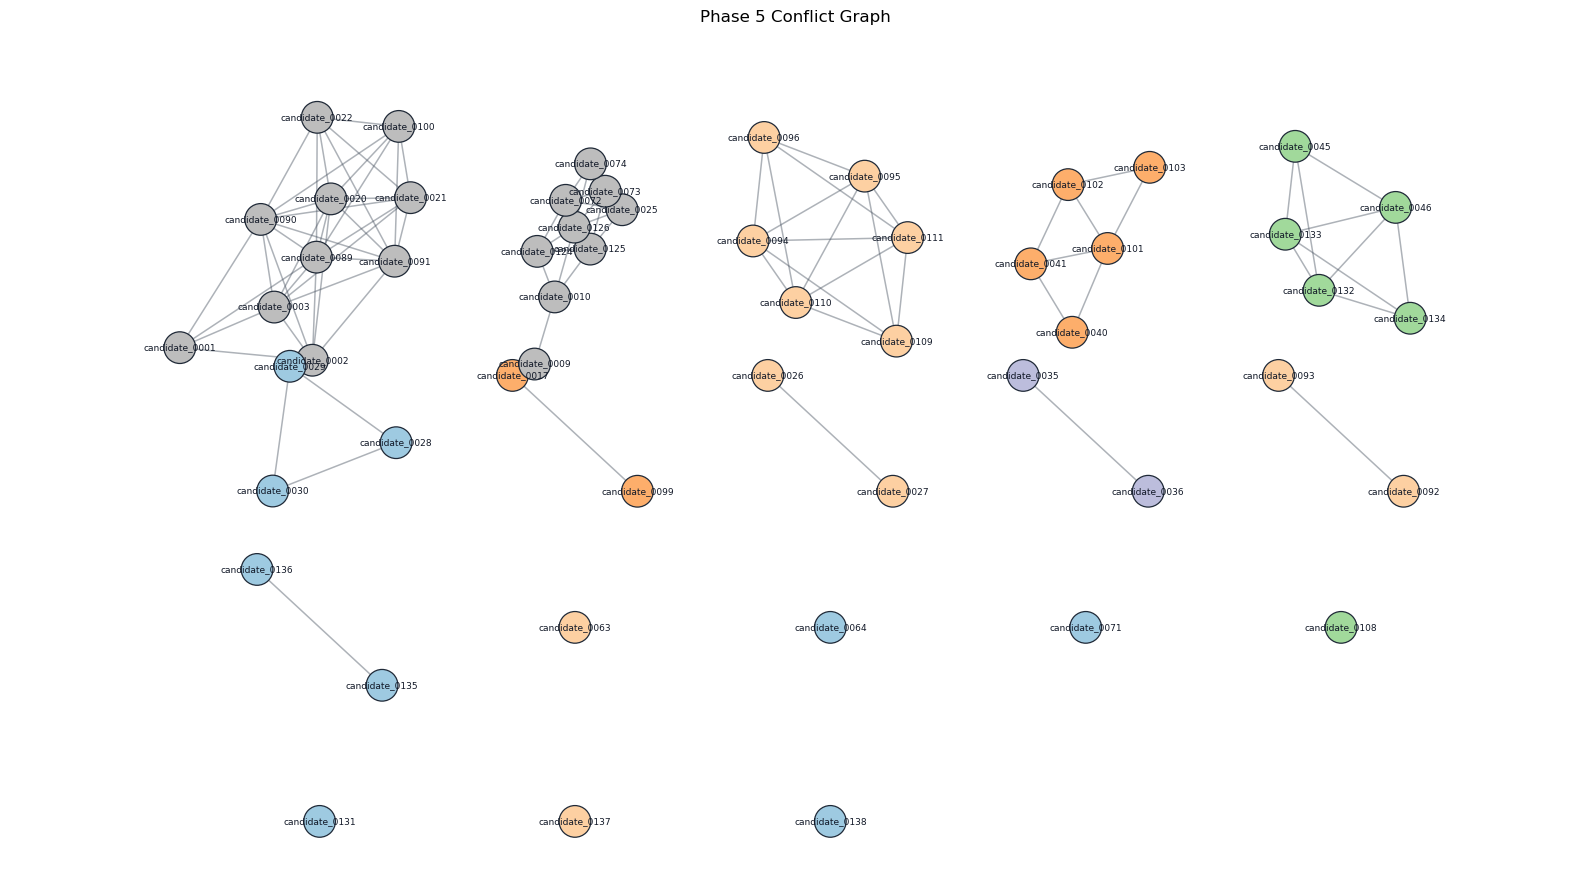

In [ ]:
def conflict_graph_component_layout(graph: nx.Graph) -> Dict[str, tuple[float, float]]:
    """Create a spread-out deterministic layout for connected components."""
    positions = {}
    components = sorted(
        nx.connected_components(graph),
        key=lambda component: (-len(component), sorted(component)),
    )

    if not components:
        return positions

    columns = 5
    cell_width = 5.2
    cell_height = 4.2

    for component_index, component_nodes in enumerate(components):
        subgraph = graph.subgraph(component_nodes)
        row = component_index // columns
        column = component_index % columns
        x_offset = column * cell_width
        y_offset = -row * cell_height

        if subgraph.number_of_nodes() == 1:
            node_id = next(iter(component_nodes))
            positions[node_id] = (x_offset, y_offset)
            continue

        local_scale = max(1.2, math.sqrt(subgraph.number_of_nodes()) * 0.9)
        local_positions = nx.spring_layout(
            subgraph,
            seed=42,
            k=1.1,
            scale=local_scale,
            iterations=200,
        )

        for node_id, position in local_positions.items():
            positions[node_id] = (position[0] + x_offset, position[1] + y_offset)

    return positions


def draw_conflict_graph(graph: nx.Graph) -> None:
    """Draw a compact conflict graph with slot-id-only node labels."""
    plt.figure(figsize=(16, 9))

    positions = conflict_graph_component_layout(graph)
    node_labels = {node_id: node_id for node_id in graph.nodes}

    antenna_colors = {
        "ANT-1": "#9ecae1",
        "ANT-2": "#a1d99b",
        "ANT-3": "#fdae6b",
        "ANT-4": "#fdd0a2",
        "ANT-5": "#bcbddc",
        "ANT-6": "#bdbdbd",
    }
    node_colors = [
        antenna_colors.get(graph.nodes[node_id]["antenna_id"], "#d9d9d9")
        for node_id in graph.nodes
    ]

    nx.draw_networkx_edges(
        graph,
        positions,
        width=1.1,
        edge_color="#4b5563",
        alpha=0.45,
    )
    nx.draw_networkx_nodes(
        graph,
        positions,
        node_size=520,
        node_color=node_colors,
        edgecolors="#1f2937",
        linewidths=0.9,
    )
    nx.draw_networkx_labels(
        graph,
        positions,
        labels=node_labels,
        font_size=6.5,
        font_color="#111827",
    )

    plt.title("Phase 5 Conflict Graph")
    plt.axis("off")
    plt.margins(0.08)
    plt.tight_layout()
    plt.show()


draw_conflict_graph(phase_5_graph)


## Phase 5 Validation Checkpoint

This cell verifies that the conflict graph contains the expected nodes, edges, edge reasons, and diagnostics.

In [ ]:
phase_5_diagnostics = graph_diagnostics(phase_5_graph)

assert phase_5_diagnostics["node_count"] == len(phase_5_slots)
assert phase_5_diagnostics["edge_count"] == phase_5_graph.number_of_edges()
assert phase_5_diagnostics["component_count"] == len(phase_5_diagnostics["connected_components"])
assert phase_5_diagnostics["density"] >= 0.0
assert phase_5_diagnostics["average_degree"] >= 0.0

for first_node, second_node, edge_data in phase_5_graph.edges(data=True):
    assert edge_data["reason"] in {
        "same communication request",
        "same-antenna overlap",
        "same-antenna reconfiguration time",
    }

print("Phase 5 validation passed: conflict graph builds correctly from the shared dataset.")

source_interval_conflict_count = sum(
    1
    for _, _, edge_data in phase_5_graph.edges(data=True)
    if edge_data["reason"] == "same communication request"
)
print({"same_request_conflict_edges": source_interval_conflict_count})


Phase 5 validation passed: conflict graph builds correctly from the shared dataset.
{'same_request_conflict_edges': 37}


## Phase 6: MWIS Validation and Classical Reference

This phase validates the maximum-weight independent set abstraction and computes a classical reference solution for the conflict graph. The QUBO translation comes in Phase 7.

In the conflict graph:
- selecting a node means selecting the corresponding candidate slot,
- node weights are slot values,
- and conflict edges enforce that incompatible slots cannot both be selected.

Therefore, a feasible schedule corresponds to an independent set, and the best schedule under this simplified model corresponds to a maximum-weight independent set.


## Classical MWIS Reference Solver

MWIS is NP-hard, so this is not meant to replace the later QUBO/annealing path. It is a classical benchmark used to check that the graph abstraction behaves as expected on our current test instance.

The implementation uses a standard graph transformation already available through NetworkX:

- an independent set in graph `G` is a clique in the complement graph `not G`,
- so MWIS on `G` becomes maximum-weight clique on the complement graph,
- and the resulting node set can be mapped back to candidate slots.

NetworkX 2.8 expects integer clique weights, so Phase 6 scales the float slot weights only inside the reference solver. The reported objective still uses the original float weights.

A tiny exact enumeration fallback is kept only for very small validation graphs.


In [ ]:
def is_independent_node_set(graph: nx.Graph, selected_node_ids: set[str]) -> bool:
    """Return True when no selected node pair is connected by a conflict edge."""
    for first_node, second_node in combinations(selected_node_ids, 2):
        if graph.has_edge(first_node, second_node):
            return False

    return True


def compute_node_set_weight(graph: nx.Graph, selected_node_ids: set[str]) -> float:
    """Compute the total graph weight of selected nodes."""
    return sum(graph.nodes[node_id]["weight"] for node_id in selected_node_ids)


def solve_mwis_by_enumeration(graph: nx.Graph) -> Dict[str, object]:
    """Solve MWIS exactly by enumerating all node subsets.

    This fallback is exponential and intended only for small validation graphs.
    """
    node_ids = sorted(graph.nodes)
    best_selected_node_ids = set()
    best_objective_value = 0.0

    for subset_size in range(len(node_ids) + 1):
        for node_subset in combinations(node_ids, subset_size):
            selected_node_ids = set(node_subset)

            if not is_independent_node_set(graph, selected_node_ids):
                continue

            objective_value = compute_node_set_weight(graph, selected_node_ids)
            if objective_value > best_objective_value:
                best_selected_node_ids = selected_node_ids
                best_objective_value = objective_value

    return {
        "selected_node_ids": best_selected_node_ids,
        "objective_value": best_objective_value,
        "solver": "exact enumeration fallback",
        "status": "optimal",
    }


def solve_mwis_with_networkx_clique(
    graph: nx.Graph,
    weight_scale: int = 1000,
) -> Dict[str, object]:
    """Solve MWIS exactly as maximum-weight clique on the complement graph.

    NetworkX 2.8 expects integer clique weights, so float slot weights are
    scaled for the solver while the returned objective uses the original
    graph weights.
    """
    complement_graph = nx.complement(graph)

    for node_id, node_data in graph.nodes(data=True):
        complement_graph.nodes[node_id]["scaled_weight"] = int(
            round(node_data["weight"] * weight_scale)
        )

    selected_node_ids, scaled_objective_value = nx.algorithms.clique.max_weight_clique(
        complement_graph,
        weight="scaled_weight",
    )

    selected_node_ids = set(selected_node_ids)
    return {
        "selected_node_ids": selected_node_ids,
        "objective_value": compute_node_set_weight(graph, selected_node_ids),
        "solver": "NetworkX exact max-weight clique on complement graph",
        "status": "optimal",
        "weight_scale": weight_scale,
        "reported_scaled_clique_weight": scaled_objective_value,
    }


def solve_mwis_classically(graph: nx.Graph) -> Dict[str, object]:
    """Compute a classical reference MWIS solution for validation."""
    try:
        return solve_mwis_with_networkx_clique(graph)
    except Exception as error:
        if graph.number_of_nodes() > 25:
            raise RuntimeError(
                "NetworkX clique solving failed and enumeration would be too expensive "
                f"for {graph.number_of_nodes()} nodes."
            ) from error

        fallback_result = solve_mwis_by_enumeration(graph)
        fallback_result["fallback_reason"] = str(error)
        return fallback_result


## Schedule Reconstruction and Feasibility Check

After solving MWIS, the selected graph nodes are mapped back to `CandidateSlot` objects. The reconstructed schedule is then checked directly against the simplified Phase 5 conflict rules.

In [ ]:
def reconstruct_selected_schedule(graph: nx.Graph, selected_node_ids: set[str]) -> list[CandidateSlot]:
    """Map selected graph node ids back to candidate slots."""
    return [graph.nodes[node_id]["slot"] for node_id in sorted(selected_node_ids)]


def check_schedule_feasibility(
    selected_slots: list[CandidateSlot],
) -> tuple[bool, list[Dict[str, str]]]:
    """Check selected slots against overlap and antenna-specific reconfiguration conflicts."""
    conflicts = []

    for first_slot, second_slot in combinations(selected_slots, 2):
        if same_source_interval_conflict(first_slot, second_slot):
            conflicts.append(
                {
                    "first_slot_id": first_slot.slot_id,
                    "second_slot_id": second_slot.slot_id,
                    "reason": "same communication request",
                }
            )
        elif same_antenna_overlap_conflict(first_slot, second_slot):
            conflicts.append(
                {
                    "first_slot_id": first_slot.slot_id,
                    "second_slot_id": second_slot.slot_id,
                    "reason": "same-antenna overlap",
                }
            )
        elif same_antenna_reconfiguration_conflict(first_slot, second_slot):
            conflicts.append(
                {
                    "first_slot_id": first_slot.slot_id,
                    "second_slot_id": second_slot.slot_id,
                    "reason": "same-antenna reconfiguration time",
                }
            )

    return len(conflicts) == 0, conflicts


def validate_mwis_solution(
    graph: nx.Graph,
    selected_node_ids: set[str],
) -> Dict[str, object]:
    """Validate the MWIS solution against graph and schedule constraints."""
    selected_slots = reconstruct_selected_schedule(graph, selected_node_ids)
    schedule_is_feasible, schedule_conflicts = check_schedule_feasibility(selected_slots)

    return {
        "is_independent_set": is_independent_node_set(graph, selected_node_ids),
        "schedule_is_feasible": schedule_is_feasible,
        "schedule_conflicts": schedule_conflicts,
        "objective_value": compute_node_set_weight(graph, selected_node_ids),
        "selected_slot_count": len(selected_node_ids),
    }


## Phase 6 Shared Dataset Benchmark

The classical MWIS reference solver optimizes the conflict graph produced from the shared dataset. The selected nodes are mapped back to candidate slots and checked for feasibility. This gives us a reference answer to compare against the later QUBO/quantum path.


In [ ]:
phase_6_solution = solve_mwis_classically(phase_5_graph)
phase_6_selected_slots = reconstruct_selected_schedule(
    phase_5_graph,
    phase_6_solution["selected_node_ids"],
)
phase_6_validation = validate_mwis_solution(
    phase_5_graph,
    phase_6_solution["selected_node_ids"],
)

print("Classical MWIS result:")
print({"solver": phase_6_solution["solver"], "status": phase_6_solution["status"]})
print({"selected_nodes": sorted(phase_6_solution["selected_node_ids"])})
print({"objective_value": phase_6_solution["objective_value"]})
print({"validation": phase_6_validation})

print("\nSelected schedule:")
for slot in phase_6_selected_slots:
    print(slot.as_dict())


Classical MWIS result:
{'solver': 'NetworkX exact max-weight clique on complement graph', 'status': 'optimal'}
{'selected_nodes': ['candidate_0001', 'candidate_0009', 'candidate_0017', 'candidate_0027', 'candidate_0030', 'candidate_0036', 'candidate_0040', 'candidate_0045', 'candidate_0063', 'candidate_0064', 'candidate_0071', 'candidate_0073', 'candidate_0091', 'candidate_0093', 'candidate_0096', 'candidate_0102', 'candidate_0108', 'candidate_0109', 'candidate_0124', 'candidate_0131', 'candidate_0134', 'candidate_0136', 'candidate_0137', 'candidate_0138']}
{'objective_value': 424.695}
{'validation': {'is_independent_set': True, 'schedule_is_feasible': True, 'schedule_conflicts': [], 'objective_value': 424.695, 'selected_slot_count': 24}}

Selected schedule:
{'slot_id': 'candidate_0001', 'source_interval_id': 'raw_001', 'satellite_id': 'SAT-005', 'antenna_id': 'ANT-6', 'station_id': 'STATION-WEST', 'reconfiguration_time': 0.18, 'start_time': 0.7, 'end_time': 1.02, 'duration': 0.3200000

## Phase 6 MWIS Solution Visualization

The selected MWIS nodes are highlighted on top of the Phase 5 conflict graph. This keeps the full conflict context visible while making the classical solution easy to inspect. Selected nodes should not have conflict edges between each other.


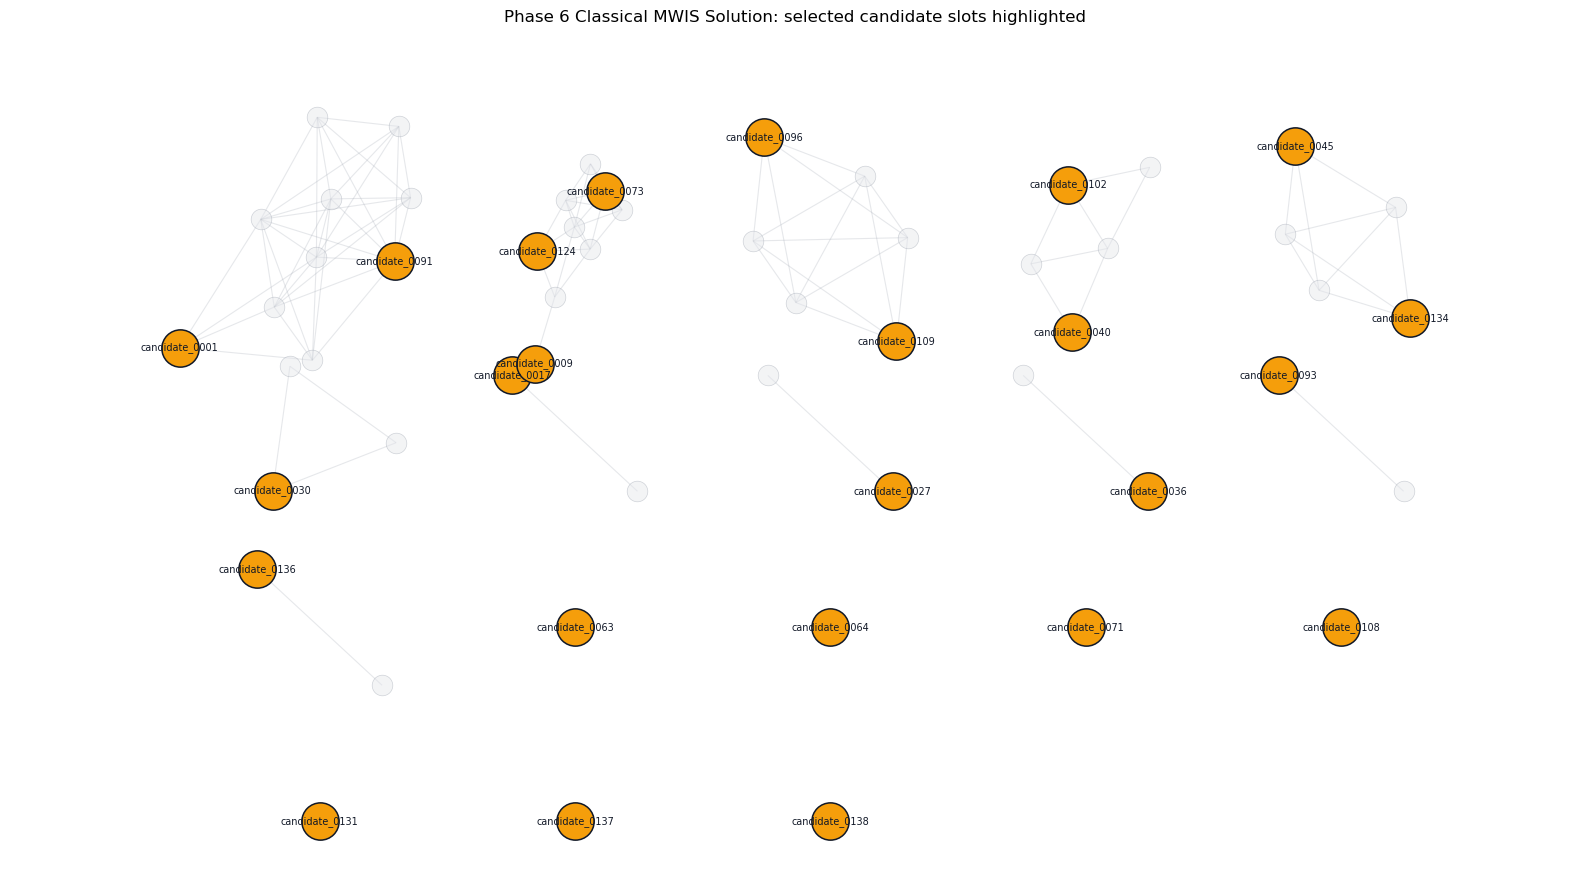

In [ ]:
def draw_mwis_solution_graph(
    graph: nx.Graph,
    selected_node_ids: set[str],
) -> None:
    """Draw the conflict graph with the MWIS solution highlighted."""
    positions = conflict_graph_component_layout(graph)

    selected_node_ids = set(selected_node_ids)
    non_selected_node_ids = [node_id for node_id in graph.nodes if node_id not in selected_node_ids]
    selected_node_list = [node_id for node_id in graph.nodes if node_id in selected_node_ids]

    selected_edges = [
        (first_node, second_node)
        for first_node, second_node in graph.edges
        if first_node in selected_node_ids and second_node in selected_node_ids
    ]
    context_edges = [
        (first_node, second_node)
        for first_node, second_node in graph.edges
        if (first_node, second_node) not in selected_edges
    ]

    plt.figure(figsize=(16, 9))

    nx.draw_networkx_edges(
        graph,
        positions,
        edgelist=context_edges,
        width=0.8,
        edge_color="#9ca3af",
        alpha=0.25,
    )

    # This should draw nothing for a valid independent set, but it makes any
    # accidental selected-selected conflict visually obvious.
    nx.draw_networkx_edges(
        graph,
        positions,
        edgelist=selected_edges,
        width=2.4,
        edge_color="#dc2626",
        alpha=0.9,
    )

    nx.draw_networkx_nodes(
        graph,
        positions,
        nodelist=non_selected_node_ids,
        node_size=220,
        node_color="#e5e7eb",
        edgecolors="#9ca3af",
        linewidths=0.5,
        alpha=0.45,
    )
    nx.draw_networkx_nodes(
        graph,
        positions,
        nodelist=selected_node_list,
        node_size=720,
        node_color="#f59e0b",
        edgecolors="#111827",
        linewidths=1.1,
    )

    nx.draw_networkx_labels(
        graph,
        positions,
        labels={node_id: node_id for node_id in selected_node_list},
        font_size=7,
        font_color="#111827",
    )

    plt.title("Phase 6 Classical MWIS Solution: selected candidate slots highlighted")
    plt.axis("off")
    plt.margins(0.08)
    plt.tight_layout()
    plt.show()


draw_mwis_solution_graph(
    phase_5_graph,
    phase_6_solution["selected_node_ids"],
)


## Phase 6 Validation Checkpoint

This cell checks that the classical reference solution is independent and feasible for the shared dataset graph.


In [ ]:
assert phase_6_validation["is_independent_set"] is True
assert phase_6_validation["schedule_is_feasible"] is True
assert phase_6_validation["schedule_conflicts"] == []
assert math.isclose(phase_6_solution["objective_value"], phase_6_validation["objective_value"])
assert phase_6_validation["selected_slot_count"] == len(phase_6_selected_slots)

print("Phase 6 validation passed: classical MWIS solution is feasible for the shared dataset.")


Phase 6 validation passed: classical MWIS solution is feasible for the shared dataset.


## Phase 7: QUBO Construction

This phase translates the MWIS conflict graph into QUBO form. We are not sampling or solving the QUBO yet; that comes after we choose QPU-sized subproblems.

For one binary variable `x_i` per graph node:

- `x_i = 1` means candidate slot `i` is selected,
- the linear term `-weight_i * x_i` rewards selecting valuable nodes,
- the quadratic term `penalty * x_i * x_j` punishes selecting both endpoints of a conflict edge.

The minimization energy is:

```text
E(x) = -sum(weight_i * x_i) + penalty * sum(x_i * x_j for every conflict edge)
```

For any conflict-free independent set, the penalty term is zero and the QUBO energy is simply the negative schedule objective.


## QUBO Builder

The QUBO is represented as a dictionary keyed by variable pairs:

- `(node_id, node_id)` stores a linear coefficient,
- `(first_node_id, second_node_id)` stores a quadratic conflict coefficient.

Because QUBO solvers minimize energy, node weights become negative diagonal coefficients. Conflict edges become positive quadratic penalties.


In [ ]:
Qubo = Dict[tuple[str, str], float]


def default_mwis_penalty(graph: nx.Graph, margin: float = 1.0) -> float:
    """Choose a simple penalty that dominates any single node reward."""
    if graph.number_of_nodes() == 0:
        return margin

    max_weight = max(graph.nodes[node_id]["weight"] for node_id in graph.nodes)
    return max_weight + margin


def canonical_qubo_key(first_node: str, second_node: str) -> tuple[str, str]:
    """Return a stable QUBO key for a linear or quadratic coefficient."""
    if first_node == second_node:
        return (first_node, second_node)

    return tuple(sorted((first_node, second_node)))


def build_mwis_qubo(
    graph: nx.Graph,
    penalty: float | None = None,
) -> Dict[str, object]:
    """Build a minimization QUBO for the MWIS conflict graph."""
    if penalty is None:
        penalty = default_mwis_penalty(graph)

    qubo: Qubo = {}

    for node_id, node_data in graph.nodes(data=True):
        qubo[(node_id, node_id)] = -float(node_data["weight"])

    for first_node, second_node in graph.edges:
        key = canonical_qubo_key(first_node, second_node)
        qubo[key] = qubo.get(key, 0.0) + float(penalty)

    return {
        "qubo": qubo,
        "variables": sorted(graph.nodes),
        "penalty": penalty,
        "offset": 0.0,
    }


## QUBO Diagnostics and Energy Evaluation

These helper functions make the QUBO readable and testable before any quantum or heuristic sampler is introduced.


In [ ]:
def selected_nodes_to_binary_sample(
    variables: list[str],
    selected_node_ids: set[str],
) -> Dict[str, int]:
    """Convert a set of selected graph nodes into a binary sample dictionary."""
    return {
        variable: 1 if variable in selected_node_ids else 0
        for variable in variables
    }


def evaluate_qubo_energy(qubo_model: Dict[str, object], sample: Dict[str, int]) -> float:
    """Evaluate QUBO energy for a binary sample."""
    energy = float(qubo_model["offset"])

    for (first_node, second_node), coefficient in qubo_model["qubo"].items():
        energy += coefficient * sample[first_node] * sample[second_node]

    return energy


def qubo_diagnostics(qubo_model: Dict[str, object]) -> Dict[str, object]:
    """Report compact diagnostics for a QUBO model."""
    qubo = qubo_model["qubo"]
    linear_coefficients = [
        coefficient
        for (first_node, second_node), coefficient in qubo.items()
        if first_node == second_node
    ]
    quadratic_coefficients = [
        coefficient
        for (first_node, second_node), coefficient in qubo.items()
        if first_node != second_node
    ]
    all_coefficients = linear_coefficients + quadratic_coefficients

    return {
        "num_variables": len(qubo_model["variables"]),
        "num_linear_terms": len(linear_coefficients),
        "num_quadratic_couplings": len(quadratic_coefficients),
        "penalty": qubo_model["penalty"],
        "linear_coefficient_range": (
            min(linear_coefficients),
            max(linear_coefficients),
        ) if linear_coefficients else None,
        "quadratic_coefficient_range": (
            min(quadratic_coefficients),
            max(quadratic_coefficients),
        ) if quadratic_coefficients else None,
        "coefficient_range": (
            min(all_coefficients),
            max(all_coefficients),
        ) if all_coefficients else None,
    }


def format_qubo_terms(
    qubo_model: Dict[str, object],
    max_terms: int = 20,
) -> list[dict[str, object]]:
    """Return readable QUBO terms for notebook display."""
    formatted_terms = []
    for (first_node, second_node), coefficient in sorted(qubo_model["qubo"].items()):
        formatted_terms.append(
            {
                "term": (first_node, second_node),
                "type": "linear" if first_node == second_node else "quadratic",
                "coefficient": coefficient,
            }
        )

    return formatted_terms[:max_terms]


## Phase 7 Small Test Case

The small graph verifies the QUBO mapping in a case where the correct MWIS is easy to inspect.


In [ ]:
phase_7_test_graph = nx.Graph()
phase_7_test_graph.add_node("A", weight=5.0)
phase_7_test_graph.add_node("B", weight=4.0)
phase_7_test_graph.add_node("C", weight=3.0)
phase_7_test_graph.add_edge("A", "B", reason="test conflict")

phase_7_test_penalty = default_mwis_penalty(phase_7_test_graph)
phase_7_test_qubo = build_mwis_qubo(
    phase_7_test_graph,
    penalty=phase_7_test_penalty,
)
phase_7_test_mwis = solve_mwis_by_enumeration(phase_7_test_graph)
phase_7_test_sample = selected_nodes_to_binary_sample(
    phase_7_test_qubo["variables"],
    phase_7_test_mwis["selected_node_ids"],
)
phase_7_test_energy = evaluate_qubo_energy(
    phase_7_test_qubo,
    phase_7_test_sample,
)

print("Small QUBO diagnostics:")
print(qubo_diagnostics(phase_7_test_qubo))
print("Small QUBO terms:")
for term in format_qubo_terms(phase_7_test_qubo):
    print(term)
print("Small graph MWIS solution:")
print(phase_7_test_mwis)
print({"qubo_energy_for_mwis": phase_7_test_energy})


Small QUBO diagnostics:
{'num_variables': 3, 'num_linear_terms': 3, 'num_quadratic_couplings': 1, 'penalty': 6.0, 'linear_coefficient_range': (-5.0, -3.0), 'quadratic_coefficient_range': (6.0, 6.0), 'coefficient_range': (-5.0, 6.0)}
Small QUBO terms:
{'term': ('A', 'A'), 'type': 'linear', 'coefficient': -5.0}
{'term': ('A', 'B'), 'type': 'quadratic', 'coefficient': 6.0}
{'term': ('B', 'B'), 'type': 'linear', 'coefficient': -4.0}
{'term': ('C', 'C'), 'type': 'linear', 'coefficient': -3.0}
Small graph MWIS solution:
{'selected_node_ids': {'A', 'C'}, 'objective_value': 8.0, 'solver': 'exact enumeration fallback', 'status': 'optimal'}
{'qubo_energy_for_mwis': -8.0}


## Phase 7 Shared Dataset QUBO

The shared-dataset QUBO is built from the Phase 5 conflict graph. The Phase 6 classical reference solution should have QUBO energy equal to its negative objective value, because it is an independent set and therefore pays no conflict penalty.


In [ ]:
PHASE_7_QUBO_PENALTY = default_mwis_penalty(phase_5_graph)

phase_7_qubo = build_mwis_qubo(
    phase_5_graph,
    penalty=PHASE_7_QUBO_PENALTY,
)
phase_7_diagnostics = qubo_diagnostics(phase_7_qubo)
phase_7_classical_sample = selected_nodes_to_binary_sample(
    phase_7_qubo["variables"],
    phase_6_solution["selected_node_ids"],
)
phase_7_classical_energy = evaluate_qubo_energy(
    phase_7_qubo,
    phase_7_classical_sample,
)

print("Shared dataset QUBO diagnostics:")
print(phase_7_diagnostics)
print("First 20 QUBO terms:")
for term in format_qubo_terms(phase_7_qubo, max_terms=20):
    print(term)
print({
    "phase_6_objective_value": phase_6_solution["objective_value"],
    "phase_7_energy_for_phase_6_solution": phase_7_classical_energy,
})


Shared dataset QUBO diagnostics:
{'num_variables': 55, 'num_linear_terms': 55, 'num_quadratic_couplings': 94, 'penalty': 30.37, 'linear_coefficient_range': (-29.37, -6.365000000000002), 'quadratic_coefficient_range': (30.37, 30.37), 'coefficient_range': (-29.37, 30.37)}
First 20 QUBO terms:
{'term': ('candidate_0001', 'candidate_0001'), 'type': 'linear', 'coefficient': -22.83}
{'term': ('candidate_0001', 'candidate_0002'), 'type': 'quadratic', 'coefficient': 30.37}
{'term': ('candidate_0001', 'candidate_0003'), 'type': 'quadratic', 'coefficient': 30.37}
{'term': ('candidate_0001', 'candidate_0089'), 'type': 'quadratic', 'coefficient': 30.37}
{'term': ('candidate_0001', 'candidate_0090'), 'type': 'quadratic', 'coefficient': 30.37}
{'term': ('candidate_0002', 'candidate_0002'), 'type': 'linear', 'coefficient': -22.83}
{'term': ('candidate_0002', 'candidate_0003'), 'type': 'quadratic', 'coefficient': 30.37}
{'term': ('candidate_0002', 'candidate_0020'), 'type': 'quadratic', 'coefficient':

## Phase 7 Validation Checkpoint

This cell checks that the QUBO has one variable per graph node, one quadratic coupling per conflict edge, and that the Phase 6 independent set maps to the expected QUBO energy.


In [ ]:
assert phase_7_diagnostics["num_variables"] == phase_5_graph.number_of_nodes()
assert phase_7_diagnostics["num_linear_terms"] == phase_5_graph.number_of_nodes()
assert phase_7_diagnostics["num_quadratic_couplings"] == phase_5_graph.number_of_edges()
assert phase_7_diagnostics["penalty"] > max(
    phase_5_graph.nodes[node_id]["weight"] for node_id in phase_5_graph.nodes
)
assert math.isclose(
    phase_7_classical_energy,
    -phase_6_solution["objective_value"],
    rel_tol=1e-9,
    abs_tol=1e-9,
)

assert phase_7_test_mwis["selected_node_ids"] == {"A", "C"}
assert math.isclose(
    phase_7_test_energy,
    -phase_7_test_mwis["objective_value"],
    rel_tol=1e-9,
    abs_tol=1e-9,
)

print("Phase 7 validation passed: MWIS conflict graph translates into a readable QUBO.")


Phase 7 validation passed: MWIS conflict graph translates into a readable QUBO.


## Phase 8: QPU-Suitable Subproblem Selection

Phase 8 prepares QUBO subproblems that are small enough to send to a quantum annealing workflow in later phases. This phase only implements the first strategy from the implementation plan: connected-component decomposition.

The key idea is that disconnected components of the conflict graph do not interact. If there is no edge between two components, selecting nodes in one component cannot create a conflict with nodes in the other component. That makes each connected component a natural independent subproblem.

## Connected-Component Subproblem Functions

These helpers extract connected components, compute descriptors for each induced subgraph, and rank/filter candidate subproblems using configurable size limits. The limits are intentionally parameters because actual QPU suitability depends on the hardware, embedding, and solver configuration used later.

In [ ]:
def sorted_connected_components_by_id(graph: nx.Graph) -> list[set[str]]:
    """Return connected components in deterministic order."""
    components = [set(component) for component in nx.connected_components(graph)]
    return sorted(components, key=lambda component: sorted(component)[0])


def edge_reason_counts(graph: nx.Graph) -> Dict[str, int]:
    """Count edge reasons inside a graph or subgraph."""
    reason_counts: Dict[str, int] = {}
    for _, _, edge_data in graph.edges(data=True):
        reason = edge_data.get("reason", "unknown")
        reason_counts[reason] = reason_counts.get(reason, 0) + 1

    return dict(sorted(reason_counts.items()))


def component_subgraph_descriptor(
    component_id: str,
    component_graph: nx.Graph,
) -> Dict[str, object]:
    """Compute readable descriptors for one connected-component subproblem."""
    node_ids = sorted(component_graph.nodes)
    node_count = component_graph.number_of_nodes()
    edge_count = component_graph.number_of_edges()
    degrees = dict(component_graph.degree())
    weights = [component_graph.nodes[node_id]["weight"] for node_id in node_ids]
    satellite_ids = {
        component_graph.nodes[node_id].get("satellite_id")
        for node_id in node_ids
        if component_graph.nodes[node_id].get("satellite_id") is not None
    }
    antenna_ids = {
        component_graph.nodes[node_id].get("antenna_id")
        for node_id in node_ids
        if component_graph.nodes[node_id].get("antenna_id") is not None
    }
    source_interval_ids = {
        component_graph.nodes[node_id].get("source_interval_id")
        for node_id in node_ids
        if component_graph.nodes[node_id].get("source_interval_id") is not None
    }

    return {
        "component_id": component_id,
        "node_count": node_count,
        "edge_count": edge_count,
        "density": nx.density(component_graph),
        "average_degree": 0.0 if node_count == 0 else sum(degrees.values()) / node_count,
        "max_degree": 0 if not degrees else max(degrees.values()),
        "total_weight": sum(weights),
        "max_weight": None if not weights else max(weights),
        "satellite_count": len(satellite_ids),
        "antenna_count": len(antenna_ids),
        "source_interval_count": len(source_interval_ids),
        "edge_reason_counts": edge_reason_counts(component_graph),
        "qubo_variable_count": node_count,
        "qubo_coupler_count": edge_count,
        "node_ids": node_ids,
    }


def mark_qpu_suitability(
    descriptor: Dict[str, object],
    max_variables: int,
    max_couplers: int,
    min_variables: int = 1,
) -> Dict[str, object]:
    """Add QPU suitability flags to a subproblem descriptor."""
    reasons = []

    if descriptor["node_count"] < min_variables:
        reasons.append(f"below minimum variable count {min_variables}")
    if descriptor["node_count"] > max_variables:
        reasons.append(f"exceeds max_variables={max_variables}")
    if descriptor["edge_count"] > max_couplers:
        reasons.append(f"exceeds max_couplers={max_couplers}")

    descriptor = dict(descriptor)
    descriptor["qpu_suitable"] = len(reasons) == 0
    descriptor["suitability_reasons"] = reasons if reasons else ["fits configured limits"]
    return descriptor


def extract_connected_component_subproblems(
    graph: nx.Graph,
    max_variables: int,
    max_couplers: int,
    min_variables: int = 1,
    penalty: float | None = None,
) -> list[Dict[str, object]]:
    """Extract connected-component subproblems and build a QUBO for each one."""
    subproblems = []

    for component_index, node_ids in enumerate(sorted_connected_components_by_id(graph), start=1):
        component_id = f"component_{component_index:03d}"
        component_graph = graph.subgraph(sorted(node_ids)).copy()
        component_graph.graph["component_id"] = component_id

        descriptor = component_subgraph_descriptor(component_id, component_graph)
        descriptor = mark_qpu_suitability(
            descriptor,
            max_variables=max_variables,
            max_couplers=max_couplers,
            min_variables=min_variables,
        )
        subproblem_qubo = build_mwis_qubo(
            component_graph,
            penalty=penalty if penalty is not None else default_mwis_penalty(component_graph),
        )

        subproblems.append(
            {
                "component_id": component_id,
                "graph": component_graph,
                "descriptor": descriptor,
                "qubo": subproblem_qubo,
            }
        )

    return subproblems


def rank_qpu_subproblems(subproblems: list[Dict[str, object]]) -> list[Dict[str, object]]:
    """Rank suitable subproblems first, then prefer larger and higher-weight components."""
    return sorted(
        subproblems,
        key=lambda subproblem: (
            subproblem["descriptor"]["qpu_suitable"],
            subproblem["descriptor"]["node_count"],
            subproblem["descriptor"]["total_weight"],
            subproblem["descriptor"]["edge_count"],
        ),
        reverse=True,
    )


def format_subproblem_descriptor(
    descriptor: Dict[str, object],
    include_nodes: bool = False,
) -> Dict[str, object]:
    """Return a compact descriptor for notebook display."""
    display_descriptor = dict(descriptor)
    if not include_nodes:
        display_descriptor.pop("node_ids", None)

    return display_descriptor


## Phase 8 Small Test Case

The small graph below has three connected components. It verifies that the extractor separates independent pieces of the graph before we apply it to the shared dataset.

In [ ]:
phase_8_test_graph = nx.Graph()
phase_8_test_graph.add_node("A", weight=5.0)
phase_8_test_graph.add_node("B", weight=4.0)
phase_8_test_graph.add_node("C", weight=3.0)
phase_8_test_graph.add_node("D", weight=6.0)
phase_8_test_graph.add_node("E", weight=2.0)
phase_8_test_graph.add_node("F", weight=1.0)

phase_8_test_graph.add_edge("A", "B", reason="test conflict")
phase_8_test_graph.add_edge("C", "D", reason="test conflict")
phase_8_test_graph.add_edge("D", "E", reason="test conflict")

phase_8_test_subproblems = extract_connected_component_subproblems(
    phase_8_test_graph,
    max_variables=3,
    max_couplers=3,
)
phase_8_test_ranked_subproblems = rank_qpu_subproblems(phase_8_test_subproblems)

print("Phase 8 small-graph subproblems:")
for subproblem in phase_8_test_ranked_subproblems:
    print(format_subproblem_descriptor(subproblem["descriptor"], include_nodes=True))


Phase 8 small-graph subproblems:
{'component_id': 'component_002', 'node_count': 3, 'edge_count': 2, 'density': 0.6666666666666666, 'average_degree': 1.3333333333333333, 'max_degree': 2, 'total_weight': 11.0, 'max_weight': 6.0, 'satellite_count': 0, 'antenna_count': 0, 'source_interval_count': 0, 'edge_reason_counts': {'test conflict': 2}, 'qubo_variable_count': 3, 'qubo_coupler_count': 2, 'node_ids': ['C', 'D', 'E'], 'qpu_suitable': True, 'suitability_reasons': ['fits configured limits']}
{'component_id': 'component_001', 'node_count': 2, 'edge_count': 1, 'density': 1.0, 'average_degree': 1.0, 'max_degree': 1, 'total_weight': 9.0, 'max_weight': 5.0, 'satellite_count': 0, 'antenna_count': 0, 'source_interval_count': 0, 'edge_reason_counts': {'test conflict': 1}, 'qubo_variable_count': 2, 'qubo_coupler_count': 1, 'node_ids': ['A', 'B'], 'qpu_suitable': True, 'suitability_reasons': ['fits configured limits']}
{'component_id': 'component_003', 'node_count': 1, 'edge_count': 0, 'density': 

## Phase 8 Shared Dataset Subproblems

The shared dataset subproblems come directly from the Phase 5 conflict graph. Each subproblem also gets its own QUBO representation using the same penalty as the full Phase 7 QUBO, keeping coefficient scaling consistent for later comparison.

In [ ]:
PHASE_8_MAX_QPU_VARIABLES = 30
PHASE_8_MAX_QPU_COUPLERS = 120
PHASE_8_MIN_QPU_VARIABLES = 2

phase_8_subproblems = extract_connected_component_subproblems(
    phase_5_graph,
    max_variables=PHASE_8_MAX_QPU_VARIABLES,
    max_couplers=PHASE_8_MAX_QPU_COUPLERS,
    min_variables=PHASE_8_MIN_QPU_VARIABLES,
    penalty=PHASE_7_QUBO_PENALTY,
)
phase_8_ranked_subproblems = rank_qpu_subproblems(phase_8_subproblems)
phase_8_suitable_subproblems = [
    subproblem
    for subproblem in phase_8_ranked_subproblems
    if subproblem["descriptor"]["qpu_suitable"]
]

print("Phase 8 shared-dataset subproblem summary:")
print({
    "total_components": len(phase_8_subproblems),
    "qpu_suitable_components": len(phase_8_suitable_subproblems),
    "max_variables": PHASE_8_MAX_QPU_VARIABLES,
    "max_couplers": PHASE_8_MAX_QPU_COUPLERS,
    "min_variables": PHASE_8_MIN_QPU_VARIABLES,
})

print("\nRanked candidate subproblems:")
for subproblem in phase_8_ranked_subproblems:
    print(format_subproblem_descriptor(subproblem["descriptor"]))

print("\nTop candidate subproblem node ids:")
if phase_8_suitable_subproblems:
    print(format_subproblem_descriptor(
        phase_8_suitable_subproblems[0]["descriptor"],
        include_nodes=True,
    ))


Phase 8 shared-dataset subproblem summary:
{'total_components': 18, 'qpu_suitable_components': 11, 'max_variables': 30, 'max_couplers': 120, 'min_variables': 2}

Ranked candidate subproblems:
{'component_id': 'component_001', 'node_count': 10, 'edge_count': 35, 'density': 0.7777777777777778, 'average_degree': 7.0, 'max_degree': 9, 'total_weight': 241.5, 'max_weight': 29.37, 'satellite_count': 4, 'antenna_count': 1, 'source_interval_count': 4, 'edge_reason_counts': {'same communication request': 9, 'same-antenna overlap': 22, 'same-antenna reconfiguration time': 4}, 'qubo_variable_count': 10, 'qubo_coupler_count': 35, 'qpu_suitable': True, 'suitability_reasons': ['fits configured limits']}
{'component_id': 'component_002', 'node_count': 9, 'edge_count': 21, 'density': 0.5833333333333334, 'average_degree': 4.666666666666667, 'max_degree': 7, 'total_weight': 167.35000000000002, 'max_weight': 23.810000000000002, 'satellite_count': 4, 'antenna_count': 1, 'source_interval_count': 4, 'edge_re

## Phase 8 Validation Checkpoint

This cell checks that connected-component extraction preserves graph accounting, that every subproblem has descriptors, and that each subproblem QUBO matches its component size.

In [ ]:
assert len(phase_8_test_subproblems) == 3
assert sorted(
    subproblem["descriptor"]["node_count"]
    for subproblem in phase_8_test_subproblems
) == [1, 2, 3]

phase_8_total_nodes = sum(
    subproblem["descriptor"]["node_count"]
    for subproblem in phase_8_subproblems
)
phase_8_total_edges = sum(
    subproblem["descriptor"]["edge_count"]
    for subproblem in phase_8_subproblems
)

assert phase_8_total_nodes == phase_5_graph.number_of_nodes()
assert phase_8_total_edges == phase_5_graph.number_of_edges()
assert len(phase_8_subproblems) == nx.number_connected_components(phase_5_graph)
assert len(phase_8_suitable_subproblems) > 0

for subproblem in phase_8_subproblems:
    descriptor = subproblem["descriptor"]
    qubo_descriptor = qubo_diagnostics(subproblem["qubo"])

    assert "component_id" in descriptor
    assert "node_ids" in descriptor
    assert descriptor["qubo_variable_count"] == descriptor["node_count"]
    assert descriptor["qubo_coupler_count"] == descriptor["edge_count"]
    assert qubo_descriptor["num_variables"] == descriptor["node_count"]
    assert qubo_descriptor["num_quadratic_couplings"] == descriptor["edge_count"]

print("Phase 8 validation passed: connected-component QPU subproblems are extracted and described.")


Phase 8 validation passed: connected-component QPU subproblems are extracted and described.


## Phase 9: Simulated Annealing Execution Wrapper

Phase 9 executes one QPU-suitable QUBO subproblem from Phase 8 using a simulated annealing backend. This is not real quantum hardware yet. It is a local annealing-style sampler that uses the same QUBO input shape we will later pass to hardware-oriented tooling.

This stage introduces the execution interface that later hardware runs will need: repeated sampling, decoding binary samples back into selected candidate slots, feasibility checks against the conflict graph, objective evaluation, and comparison against the exact classical MWIS baseline.

## Annealing Backend Import

The current backend is D-Wave Ocean's `neal.SimulatedAnnealingSampler`. It samples low-energy binary assignments for a QUBO. A lower QUBO energy should correspond to a better schedule, provided conflict penalties are large enough and the returned sample is feasible.

In [ ]:
import neal

ANNEALING_BACKEND_NAME = "neal simulated annealing"


## Decoding and Evaluation Helpers

The sampler returns a binary sample such as `{candidate_0001: 1, candidate_0002: 0}`. The helpers below decode that into selected graph nodes, evaluate the QUBO energy, check graph feasibility, and compare the sampled result with the exact MWIS solution on the same subproblem.

In [ ]:
def sample_to_selected_node_ids(sample: Dict[str, int]) -> set[str]:
    """Decode a binary QUBO sample into selected graph node ids."""
    return {
        node_id
        for node_id, value in sample.items()
        if int(value) == 1
    }


def selected_conflict_edges(
    graph: nx.Graph,
    selected_node_ids: set[str],
) -> list[tuple[str, str, str]]:
    """Return conflict edges whose endpoints are both selected."""
    conflicts = []
    for first_node, second_node, edge_data in graph.edges(data=True):
        if first_node in selected_node_ids and second_node in selected_node_ids:
            conflicts.append((first_node, second_node, edge_data.get("reason", "unknown")))

    return conflicts


def evaluate_annealing_sample(
    subproblem: Dict[str, object],
    sample: Dict[str, int],
    energy: float,
) -> Dict[str, object]:
    """Evaluate one annealer sample against the graph and QUBO model."""
    graph = subproblem["graph"]
    qubo_model = subproblem["qubo"]
    selected_node_ids = sample_to_selected_node_ids(sample)
    conflict_edges = selected_conflict_edges(graph, selected_node_ids)
    objective_value = compute_node_set_weight(graph, selected_node_ids)
    recomputed_energy = evaluate_qubo_energy(qubo_model, sample)

    return {
        "selected_node_ids": selected_node_ids,
        "selected_node_count": len(selected_node_ids),
        "objective_value": objective_value,
        "energy": float(energy),
        "recomputed_energy": recomputed_energy,
        "is_independent_set": len(conflict_edges) == 0,
        "conflict_count": len(conflict_edges),
        "conflict_edges": conflict_edges,
    }


def compare_sample_to_exact_mwis(
    subproblem: Dict[str, object],
    sample_evaluation: Dict[str, object],
) -> Dict[str, object]:
    """Compare annealer output against exact MWIS on the same component."""
    exact_solution = solve_mwis_classically(subproblem["graph"])
    exact_selected_node_ids = exact_solution["selected_node_ids"]
    exact_objective = exact_solution["objective_value"]
    sampled_objective = sample_evaluation["objective_value"]

    return {
        "exact_selected_node_ids": exact_selected_node_ids,
        "exact_objective_value": exact_objective,
        "sampled_objective_value": sampled_objective,
        "objective_gap": exact_objective - sampled_objective,
        "matches_exact_selected_set": sample_evaluation["selected_node_ids"] == exact_selected_node_ids,
        "matches_exact_objective": math.isclose(
            sampled_objective,
            exact_objective,
            rel_tol=1e-9,
            abs_tol=1e-9,
        ),
        "exact_solver": exact_solution["solver"],
    }


## Simulated Annealing Wrapper

The wrapper accepts a Phase 8 subproblem and returns one consistent result dictionary. Later, this is the function shape we can reuse for a real quantum annealing backend: the inside changes, while the rest of the notebook can keep using the same output fields.

In [ ]:
def run_neal_simulated_annealing(
    subproblem: Dict[str, object],
    num_reads: int = 200,
    seed: int | None = 42,
) -> Dict[str, object]:
    """Run D-Wave Neal's simulated annealer on one QUBO subproblem."""
    sampler = neal.SimulatedAnnealingSampler()
    response = sampler.sample_qubo(
        subproblem["qubo"]["qubo"],
        num_reads=num_reads,
        seed=seed,
    )

    best_record = response.first
    best_sample = {
        variable: int(best_record.sample[variable])
        for variable in subproblem["qubo"]["variables"]
    }
    sample_evaluation = evaluate_annealing_sample(
        subproblem,
        best_sample,
        best_record.energy,
    )
    exact_comparison = compare_sample_to_exact_mwis(
        subproblem,
        sample_evaluation,
    )

    return {
        "backend": ANNEALING_BACKEND_NAME,
        "component_id": subproblem["component_id"],
        "num_reads": num_reads,
        "seed": seed,
        "best_sample": best_sample,
        "best_energy": float(best_record.energy),
        "num_occurrences": int(best_record.num_occurrences),
        "sample_evaluation": sample_evaluation,
        "exact_comparison": exact_comparison,
        "response_info": dict(response.info),
    }


def run_annealing_subproblem(
    subproblem: Dict[str, object],
    backend: str = "neal",
    num_reads: int = 200,
    seed: int | None = 42,
) -> Dict[str, object]:
    """Run an annealing backend on a selected Phase 8 subproblem."""
    if backend != "neal":
        raise ValueError(f"Unsupported backend: {backend}")

    return run_neal_simulated_annealing(
        subproblem,
        num_reads=num_reads,
        seed=seed,
    )


## Phase 9 Run on One Selected Subproblem

We run only the top ranked Phase 8 suitable subproblem first. This keeps the execution small and makes the result easy to compare against the exact classical MWIS result for that same connected component.

In [ ]:
phase_9_selected_subproblem = phase_8_suitable_subproblems[0]

phase_9_result = run_annealing_subproblem(
    phase_9_selected_subproblem,
    backend="neal",
    num_reads=500,
    seed=42,
)

phase_9_sample_evaluation = phase_9_result["sample_evaluation"]
phase_9_exact_comparison = phase_9_result["exact_comparison"]

print("Phase 9 simulated annealing result:")
print({
    "backend": phase_9_result["backend"],
    "component_id": phase_9_result["component_id"],
    "num_reads": phase_9_result["num_reads"],
    "best_energy": phase_9_result["best_energy"],
    "num_occurrences": phase_9_result["num_occurrences"],
})

print("\nDecoded selected nodes:")
print(sorted(phase_9_sample_evaluation["selected_node_ids"]))

print("\nSample evaluation:")
print({
    "selected_node_count": phase_9_sample_evaluation["selected_node_count"],
    "objective_value": phase_9_sample_evaluation["objective_value"],
    "energy": phase_9_sample_evaluation["energy"],
    "recomputed_energy": phase_9_sample_evaluation["recomputed_energy"],
    "is_independent_set": phase_9_sample_evaluation["is_independent_set"],
    "conflict_count": phase_9_sample_evaluation["conflict_count"],
})

print("\nClassical exact comparison:")
print({
    "exact_objective_value": phase_9_exact_comparison["exact_objective_value"],
    "sampled_objective_value": phase_9_exact_comparison["sampled_objective_value"],
    "objective_gap": phase_9_exact_comparison["objective_gap"],
    "matches_exact_objective": phase_9_exact_comparison["matches_exact_objective"],
    "matches_exact_selected_set": phase_9_exact_comparison["matches_exact_selected_set"],
})


Phase 9 simulated annealing result:
{'backend': 'neal simulated annealing', 'component_id': 'component_001', 'num_reads': 500, 'best_energy': -52.20000000000016, 'num_occurrences': 1}

Decoded selected nodes:
['candidate_0001', 'candidate_0091']

Sample evaluation:
{'selected_node_count': 2, 'objective_value': 52.2, 'energy': -52.20000000000016, 'recomputed_energy': -52.2, 'is_independent_set': True, 'conflict_count': 0}

Classical exact comparison:
{'exact_objective_value': 52.2, 'sampled_objective_value': 52.2, 'objective_gap': 0.0, 'matches_exact_objective': True, 'matches_exact_selected_set': True}


## Phase 9 Validation Checkpoint

This cell verifies that the simulated annealing result decodes into a valid graph solution, that the reported energy matches our QUBO energy calculation, and that the result can be compared against the exact MWIS baseline.

In [ ]:
assert phase_9_result["backend"] == ANNEALING_BACKEND_NAME
assert phase_9_result["component_id"] == phase_9_selected_subproblem["component_id"]
assert phase_9_result["num_reads"] == 500

assert math.isclose(
    phase_9_sample_evaluation["energy"],
    phase_9_sample_evaluation["recomputed_energy"],
    rel_tol=1e-9,
    abs_tol=1e-9,
)
assert phase_9_sample_evaluation["is_independent_set"] is True
assert phase_9_sample_evaluation["conflict_count"] == 0
assert phase_9_exact_comparison["objective_gap"] >= -1e-9
assert phase_9_exact_comparison["matches_exact_objective"] is True

print("Phase 9 validation passed: simulated annealing runs one QUBO subproblem and matches the exact MWIS baseline.")


Phase 9 validation passed: simulated annealing runs one QUBO subproblem and matches the exact MWIS baseline.
